## Mutation bias and codon usage bias investigation 

## 0. General

### 0.1. Load libraries

In [1]:
import os, pandas as pd, json, numpy as np
from scipy.stats import binomtest, chisquare
from collections import defaultdict
from Bio import SeqIO
from Bio.Seq import Seq
from statsmodels.stats.multitest import multipletests

In [2]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.gridspec as gridspec

import seaborn as sns

sns.set_theme(style="white", font="Arial")
sns.set_context({'font.size': 10.0, 'axes.labelsize': 12, 'axes.titlesize': 14,
                 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.fontsize': 10,
                 'legend.title_fontsize': None, 'axes.linewidth': 0.8, 'grid.linewidth': 0.8,
                 'lines.linewidth': 1.5, 'lines.markersize': 6.0, 'patch.linewidth': 1.0,
                 'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.minor.width': 0.3,
                 'ytick.minor.width': 0.3, 'xtick.major.size': 3.5, 'ytick.major.size': 3.5,
                 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,})

plt.rcParams['xtick.bottom'] = True
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['font.size'] = 12
plt.rcParams['xtick.bottom'] = True
plt.rcParams['ytick.left'] = True


### 0.2 General variables

In [3]:
donors = [1,2,3,4]
replicates = ["A", "B", "C"]
passages = list(range(0, 110, 10))
tech_reps = [1,2 ]
populations = ["1A", "1B", "1C", "2A", "2B", "2C", "3A", "3B", "3C", "4A", "4B", "4C"]
segments = ["1-PB2", "2-PB1", "3-PA", "4-HA", "5-NP", "6-NA", "7-M", "8-NS"]
proteins = ['PB2', 'PB1', 'PB1-F2', 'PA', 'PA-X', 'HA', 'NP', 'NA', 'M1', 'M2', 'NEP', 'NS1']


hours_per_passage = 72 #hours
generation_time = 6 #hours > assumption based on Baccam, et al. 2006

In [4]:
possible_mutations_cpal = [ "#fde0ef", "#de77ae",  "#c51b7d", "#8e0152", "#d9ed92", "#b5e48c", "#76c893", "#52b69a", "#34a0a4", "#168aad", "#1e6091", "#184e77" ]


In [5]:
#TnTv ~3 for influenza Bloom, 2014 and Pauly, et al. 2017
TnTv = 3
weight_Tn = 3 * TnTv / (1 + TnTv)
weight_Tv = (3 - weight_Tn) / 2

possible_mutations = ["A>G",  "C>T", "G>A", "T>C", "A>C", "A>T", "C>A", "C>G", "G>C", "G>T", "T>A", "T>G"]


#complementary bases
comp = {"A": "T", "T": "A", "C": "G", "G": "C"}
substitution_types = ["A:T→T:A", "A:T→C:G", "A:T→G:C",
                      "C:G→T:A", "C:G→A:T", "C:G→G:C"]


codon_table = {'ATA':'I', 'ATC':'I', 'ATT':'I', 'ATG':'M', 'ACA':'T', 'ACC':'T', 'ACG':'T', 'ACT':'T', 'AAC':'N',
               'AAT':'N', 'AAA':'K', 'AAG':'K', 'AGC':'S', 'AGT':'S', 'AGA':'R', 'AGG':'R', 'CTA':'L', 'CTC':'L',
               'CTG':'L', 'CTT':'L', 'CCA':'P', 'CCC':'P', 'CCG':'P', 'CCT':'P', 'CAC':'H', 'CAT':'H', 'CAA':'Q',
               'CAG':'Q', 'CGA':'R', 'CGC':'R', 'CGG':'R', 'CGT':'R', 'GTA':'V', 'GTC':'V', 'GTG':'V', 'GTT':'V',
               'GCA':'A', 'GCC':'A', 'GCG':'A', 'GCT':'A', 'GAC':'D', 'GAT':'D', 'GAA':'E', 'GAG':'E', 'GGA':'G',
               'GGC':'G', 'GGG':'G', 'GGT':'G', 'TCA':'S', 'TCC':'S', 'TCG':'S', 'TCT':'S', 'TTC':'F', 'TTT':'F', 
               'TTA':'L', 'TTG':'L', 'TAC':'Y', 'TAT':'Y', 'TAA':'*', 'TAG':'*', 'TGC':'C', 'TGT':'C', 'TGA':'*',
               'TGG':'W'}

codons_per_aa = {}
for codon, aa in codon_table.items():
    if aa not in codons_per_aa.keys():
        codons_per_aa[aa] = []
    codons_per_aa[aa].append(codon)

In [6]:
with open('../data/CDS_H3N2.json') as json_file:
    coding_json = json.load(json_file)
segment_nuc_cds = {r.id:r.seq for r in SeqIO.parse('../data/references/stock_consensus_cds.fasta', 'fasta')}

aapos2codon = {}
nucpos2aapos = {}
for segment, pdict in coding_json.items():
    aapos2codon[segment] = {}
    nucpos2aapos[segment] = {}
    for protein, posdict in pdict.items():
        aapos2codon[segment][protein] = {}
        
        for aapos in np.arange(1, posdict["pro_aa_pos"][-1]+1):
            nucpos = [posdict["nuc_cds_pos"][i] for i, aap in enumerate(posdict["pro_aa_pos"]) if aap == aapos]
            aapos2codon[segment][protein][aapos] = nucpos
    
        nucpos2aapos[segment][protein] = {nucpos:posdict["pro_aa_pos"][i] for i, nucpos in enumerate(posdict["nuc_cds_pos"])}

        


### 0.3. Functions

In [7]:
def canonical_sub(anc, mut):
    if anc in ["A", "C"]:
        return f"{anc}:{comp[anc]}→{mut}:{comp[mut]}"
    else:
        anc2, mut2 = comp[anc], comp[mut]
        return f"{anc2}:{comp[anc2]}→{mut2}:{comp[mut2]}"

def get_base_synonymous_weights(codon):
    target_AA = str(Seq(codon).translate())
    position_weights = defaultdict(float)
    
    for position in range(3):
        ancestral_base = codon[position]
        
        for mutated_base in ["A", "C", "T", "G"]:
            if mutated_base == ancestral_base: 
                continue
            
            # Determine mutation pathway type
            mutation_pair = f"{ancestral_base}{mutated_base}"
            weight = weight_Tn if mutation_pair in ["AG", "GA", "CT", "TC"] else weight_Tv
            
            mutated_codon = codon[:position] + mutated_base + codon[position+1:]
            mutated_AA = str(Seq(mutated_codon).translate())
            
            if mutated_AA == target_AA:
                
                
                position_weights[position] += weight / 3.0
                
    return position_weights

def get_synonymous_weights_by_subtype(codon):
    target_AA = str(Seq(codon).translate())
    sub_weights = defaultdict(float)

    for position in range(3):
        ancestral_base = codon[position]
        for mutated_base in ["A", "C", "T", "G"]:
            if mutated_base == ancestral_base:
                continue

            mutation_pair = f"{ancestral_base}{mutated_base}"
            weight = weight_Tn if mutation_pair in ["AG", "GA", "CT", "TC"] else weight_Tv

            mutated_codon = codon[:position] + mutated_base + codon[position + 1:]
            mutated_AA = str(Seq(mutated_codon).translate())

            if mutated_AA == target_AA:
                sub_type = canonical_sub(ancestral_base, mutated_base)
                sub_weights[sub_type] += weight / 3.0

    return sub_weights


## 1. Mutation bias exploration

In [8]:
#load snv summary 
snv_summary = pd.read_csv("../results/snv_summary_annotated_linkage.csv", keep_default_na=False, na_values=[""]).set_index(["population", "refname", "nucpos", "snv"]).sort_index()


#create overview of non-synonymous SNVs (for convienence)
non_synonymous_dict = {segment:[] for segment in segments}
for i in snv_summary[snv_summary["non_synonymous"]==True].index.droplevel(0):
    non_synonymous_dict[i[0]].append(i[-1])
    


#creating individual df to avoid double counting SNVs that coverage multiple ORFs
nuc_changes = snv_summary[~snv_summary["protein"].isin(["PA-X", "PB1-F2"])].drop(columns=["aapos",  "protein", "aa_mut", "original_codon", "read_codon", "position_in_codon",])
nuc_changes=nuc_changes.reset_index().drop_duplicates().set_index(["population", "refname", "nucpos", "snv"]).sort_index()
#only synonymous SNV on all ORFs should be labelled non-synonomous 
nuc_changes["non_synonymous"] = [nuc_changes.loc[i, "non_synonymous"].values[0] if len(nuc_changes.loc[i]) <2 else True if i[-1] in non_synonymous_dict[i[1]] else False  for i in nuc_changes.index]


### 1.1. Visualize transition transversion (Ti/Tv) ratio from data

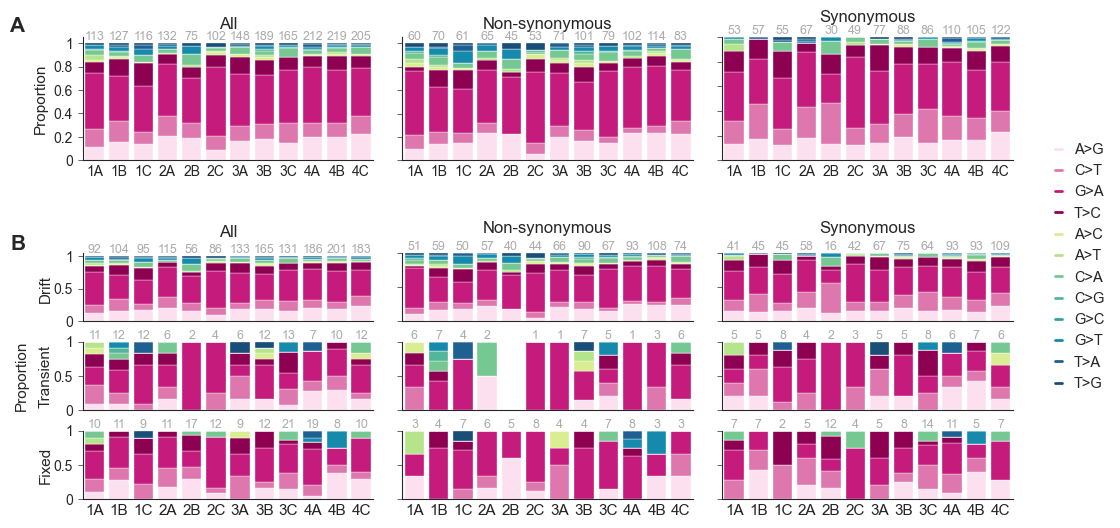

In [9]:
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(2,1, wspace=0.2, hspace=0.5, height_ratios=[1,2])


label_counts = True

legend_elements = []
for (mt, color) in zip(possible_mutations, possible_mutations_cpal):
    legend_elements.append(Line2D([0], [0], color=color, label=mt, linewidth=2,  ))

gsi = gridspec.GridSpecFromSubplotSpec(1,3, wspace=0.1, hspace=0.23, subplot_spec=gs[0])
for i, non_syn_status in enumerate([[True, False], [True], [False]]):
    ax = fig.add_subplot(gsi[i])
    df = nuc_changes[nuc_changes["non_synonymous"].isin(non_syn_status)].reset_index()
    df = df.groupby(["nuc_change", "population",])[["snv"]].count().reset_index()
    for population in populations:
        pdf = df[df["population"]==population]
        for k, r in pdf.iterrows():
            df.loc[k, "proportion"] = r["snv"]/pdf["snv"].sum()
    
    cdf = df.pivot(index="nuc_change", columns="population", values="snv").fillna(0).round(3)
    
    df = df.pivot(index="nuc_change", columns="population", values="proportion").fillna(0).round(3)
    
    for k, population in enumerate(populations):
        bottom = 0
        for l,  mt in enumerate(possible_mutations):
            try:
                c = df.loc[mt, population]
            except:
                c = 0

            p = ax.bar(k+0.5, c, bottom=bottom, color=possible_mutations_cpal[l], edgecolor=None, lw=0.25)
            bottom += c
            
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1]) 
    
    
    if label_counts: 
        for k, population in enumerate(populations):

            try:
                ax.text(k+0.5, 1, int(cdf[population].sum()) , va="bottom", ha="center", size=9, color="#ABABAB")
            except:
                continue

    if i == 0:
        ax.set_ylabel("Proportion", size=11)  
        ax.set_yticklabels([0, 0.2, 0.4, 0.6, 0.8, 1], size=10) 
        ax.text(-3, 1.1, "A", size=15, fontweight="bold")
    else:
        ax.set_yticklabels([], size=9) 

    ax.text(len(populations)/2, 1.125 if label_counts else 1.075, ['All', "Non-synonymous", "Synonymous"][i], ha="center", size=12)

    ax.spines[['top','right']].set_visible(False)

    ax.set_xticks([i+0.5 for i in range(len(populations))])
    #ax.set_xticklabels(simplified_populations, size=9)
    ax.set_xticklabels(populations, size=10)
    
   
    ax.set_xlim(0,len(populations))
    ax.tick_params(axis='x', which='both', length=0)
    
    if i == 2:
        leg = ax.legend(handles=legend_elements, loc='upper left',
                        bbox_to_anchor=(1.1,0.25), ncols =1, fontsize=10.5, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)

gsi = gridspec.GridSpecFromSubplotSpec(3, 3, wspace=0.1, hspace=0.3 if label_counts else 0.2, subplot_spec=gs[1], )
for i, non_syn_status in enumerate([[True, False], [True], [False]]):
    for j, status in enumerate(["drift", "transient", "fixed"]):
        ax = fig.add_subplot(gsi[j,i])
        
        df = nuc_changes[(nuc_changes["non_synonymous"].isin(non_syn_status))&(nuc_changes["status"]==status)].reset_index()
        df = df.groupby(["nuc_change", "population",])[["snv"]].count().reset_index()
        for population in populations:
            pdf = df[df["population"]==population]
            for k, r in pdf.iterrows():
                df.loc[k, "proportion"] = r["snv"]/pdf["snv"].sum()

        cdf = df.pivot(index="nuc_change", columns="population", values="snv").fillna(0).round(3)
        df = df.pivot(index="nuc_change", columns="population", values="proportion").fillna(0).round(3)

        for k, population in enumerate(populations):
            bottom = 0
            for l,  mt in enumerate(possible_mutations):
                try:
                    c = df.loc[mt, population]
                except:
                    c = 0
                 
                p = ax.bar(k+0.5, c, bottom=bottom, color=possible_mutations_cpal[l], edgecolor=None, lw=0.25)
                bottom += c
                     
        ax.set_yticks([0,  0.5,  1]) 
        
        if i == 0:
            #ax.set_ylabel("Proportion", size=10)  
            ax.set_yticklabels([0, 0.5, 1], size=10) 
            if j ==1:
                ax.text(-2.8, 0.5, "Proportion", rotation=90, va="center", size=11)
            ax.text(-1.8, 0.5, ["Drift", "Transient",'Fixed',][j], rotation=90, va="center", size=11)
        else:
            ax.set_yticklabels([], size=9) 
            
        if label_counts: 
            for k, population in enumerate(populations):

                try:
                    ax.text(k+0.5, 1, int(cdf[population].sum()) , va="bottom", ha="center", size=9, color="#ABABAB")
                except:
                    continue

                

        ax.spines[['top','right']].set_visible(False)

        ax.set_xticks([i+0.5 for i in range(len(populations))])
        if j ==2:
            #ax.set_xticklabels(simplified_populations, size=9)
            ax.set_xticklabels(populations, size=11)
            
        else:
            ax.set_xticklabels([])
            
        if j == 0:
            ax.text(len(populations)/2, 1.3 if label_counts else 1.2, ['All', "Non-synonymous", "Synonymous"][i], ha="center", size=12)
            

        ax.set_xlim(0,len(populations))
        ax.tick_params(axis='x', which='both', length=0)
        
        if i == 0 and j == 0:
            ax.text(-3, 1.1, "B", size=15, fontweight="bold")
  
        
fig.savefig("../figures/figE5_nucleotide_changes.svg", dpi=300,bbox_inches='tight')#
fig.savefig("../figures/figE5_nucleotide_changes.png", dpi=300,bbox_inches='tight')                  

**Extended Data Figure 5 Proportion of nucleotide changes per population.** **A**. Proportions of changes for all, non-synonymous, and synonymous SNV per population. **B**. Proportion of changes for all, non-synonymous, and synonymous substitutions separate by SNV classification. Pink shades indicated transitions and the blue green shades indicated transversions. The number above each bar indicates the number of SNVs.

### 1.2. Estimating overall Ti/Tv ratio from data

True Null expectation of Ti/Tv ratio is 0.5, as there are twice as many transversion pairs as there are transition pairs.
from literature we know that the expected Ti/Tv ratio for influenza is ~3
- bloom, 2014 estimated a transition-transversion of 3
- Pauly, et al. assumes this to be 2.7-3.6 

any higher rates (or lower) might be indicative of mutation bias


**ESTIMATING FOR SYNONYMOUS CHANGES ONLY** > including drifters as we care about the process of generating mutations here

In [10]:
#non overlapping ORFS only
syn_titv_nonoverlap = []

for population in populations:
    df = nuc_changes.loc[population]
    df = df.loc[[("1-PB2"), ("2-PB1"), ("3-PA"),("4-HA"),("5-NP"), ("6-NA")]]
    df = df[(df["non_synonymous"] == False)]
    
    ti = df[df["change_type"] == "Ti"].shape[0]  # raw count, no psuedo counting necessary
    tv = df[df["change_type"] == "Tv"].shape[0]  # raw count, no psuedo counting necessay
    n  = ti + tv

    #null: Ti/Tv = 3  => 3:1 >  p0 = 3/4 = 0.75
    p0 = 0.75
    if n > 0:
        result = binomtest(ti, n, p0, alternative='two-sided')
        p_val  = result.pvalue
    else:
        p_val  = None

    ratio = round(ti / tv, 3) if tv > 0 else None

    syn_titv_nonoverlap.append([population, ti, tv, n, ratio, p_val, p_val<0.05])

syn_titv_nonoverlap = pd.DataFrame.from_records(syn_titv_nonoverlap,columns=["population", "Ti", "Tv", "n", "Ti/Tv", "p (two-sided)", "sig"])

syn_titv_nonoverlap

,population,Ti,Tv,n,Ti/Tv,p (two-sided),sig
0,1A,43,3,46,14.333,0.001918,True
1,1B,51,1,52,51.000,0.000008,True
2,1C,43,6,49,7.167,0.046115,True
3,2A,55,2,57,27.500,0.000022,True
4,2B,21,3,24,7.000,0.236337,False
5,2C,43,3,46,14.333,0.001918,True
6,3A,62,4,66,15.500,0.000094,True
7,3B,72,7,79,10.286,0.000391,True
8,3C,67,6,73,11.167,0.000375,True
9,4A,87,9,96,9.667,0.000207,True


In [11]:
df = syn_titv_nonoverlap.copy()[['population', 'Ti', 'Tv']]
df["donor"] =[int(p[0]) for p in df["population"]]

df.to_csv("../results/TiTV_count_per_pop_non-overlapping_ORFS.csv", index=False)

In [12]:
syn_titv_overall = []

for population in populations:
    df = nuc_changes[nuc_changes["status"]=="drift"].loc[population]
    #df = df.loc[[("1-PB2"), ("2-PB1"), ("3-PA"),("4-HA"),("5-NP"), ("6-NA")]]
    df = df[(df["non_synonymous"] == False)]
    
    ti = df[df["change_type"] == "Ti"].shape[0]  # raw count, no +1
    tv = df[df["change_type"] == "Tv"].shape[0]  # raw count, no +1
    n  = ti + tv

    #null: Ti/Tv = 3  => 3:1 >  p0 = 3/4 = 0.75
    p0 = 0.75
    if n > 0:
        result = binomtest(ti, n, p0, alternative='two-sided')
        p_val  = result.pvalue
    else:
        p_val  = None

    ratio = round(ti / tv, 3) if tv > 0 else None

    syn_titv_overall.append([population, ti, tv, n, ratio, p_val, p_val<0.05])

syn_titv_overall = pd.DataFrame.from_records(syn_titv_overall,columns=["population", "Ti", 	"Tv",	"# total substitutions",	"Estimated Ti/Tv ratio",	"P (two-side binomial tests)", "sig"])

syn_titv_overall.set_index(["population"]).to_clipboard()
syn_titv_overall

,population,Ti,Tv,# total substitutions,Estimated Ti/Tv ratio,P (two-side binomial tests),sig
0,1A,37,4,41,9.250,2.843784e-02,True
1,1B,44,1,45,44.000,8.196712e-05,True
2,1C,40,5,45,8.000,3.701157e-02,True
3,2A,55,3,58,18.333,1.125232e-04,True
4,2B,13,3,16,4.333,7.748009e-01,False
5,2C,40,2,42,20.000,1.045812e-03,True
6,3A,63,4,67,15.750,9.592913e-05,True
7,3B,68,7,75,9.714,1.160581e-03,True
8,3C,60,4,64,15.000,1.408070e-04,True
9,4A,85,8,93,10.625,9.804043e-05,True


In [13]:
df = syn_titv_overall.copy()[['population', 'Ti', 'Tv']]
df["donor"] =[int(p[0]) for p in df["population"]]

df.to_csv("../results/TiTV_count_per_pop_overall.csv", index=False)

### R notebook
Same pattern across populations instead estimating the Ti/TV bias experiment-wide 

### 1.3. Identification of substitution type driving the observed Ti/Tv change

#### 1.3.1. Non-overlapping ORFs

In [14]:
#anc > ancestral
TnTv = 3
weight_Tn = 3 * TnTv / (1 + TnTv)
weight_Tv = (3 - weight_Tn) / 2

available_bases_per_syn_sites_per_gene = {}
target_genes = ["PB2", "PB1", "PA", "HA", "NP", "NA"]
available_bases_per_syn_sites =  {"A": 0.0, "C": 0.0, "G": 0.0, "T": 0.0}
for segment, sdict in coding_json.items():
    
    for gene, gdict in sdict.items():
        if gene not in target_genes: 
            continue
            
        
        available_bases_per_syn_sites_per_gene[gene] = {"A": 0.0, "C": 0.0, "G": 0.0, "T": 0.0}
        gene_seq = Seq("".join([b for i, b in enumerate(segment_nuc_cds[segment]) if i+1 in gdict['nuc_cds_pos']]))
        gene_codons = [str(gene_seq[i:i+3]) for i in range(0, len(gene_seq), 3)]
        
        for codon in gene_codons:
            if len(codon) != 3 or any(b not in "ACGT" for b in codon):
                continue

            codon_weights = get_base_synonymous_weights(codon)
            
            for position, weight in codon_weights.items():
                ancestral_base = codon[position]
                available_bases_per_syn_sites_per_gene[gene][ancestral_base] += weight
                available_bases_per_syn_sites[ancestral_base] += weight
 
#determine opportunity based on stock               
opportunity = defaultdict(float)
for segment, sdict in coding_json.items():
    for gene, gdict in sdict.items():
        if gene not in target_genes:
            continue

        gene_seq = Seq("".join([b for i, b in enumerate(segment_nuc_cds[segment])if i + 1 in gdict['nuc_cds_pos']]))
        gene_codons = [str(gene_seq[i:i + 3]) for i in range(0, len(gene_seq), 3)]

        for codon in gene_codons:
            if len(codon) != 3 or any(b not in "ACGT" for b in codon):
                continue
            for sub_type, w in get_synonymous_weights_by_subtype(codon).items():
                
                opportunity[sub_type] += w

total_opportunity = sum(opportunity.values())
                

In [15]:
weight_Tn

2.25

In [16]:
TnTv = 11.75
weight_Tn = 3 * TnTv / (1 + TnTv)
weight_Tv = (3 - weight_Tn) / 2

opportunity_estimated = defaultdict(float)
for segment, sdict in coding_json.items():
    for gene, gdict in sdict.items():
        if gene not in target_genes:
            continue

        gene_seq = Seq("".join([b for i, b in enumerate(segment_nuc_cds[segment])if i + 1 in gdict['nuc_cds_pos']]))
        gene_codons = [str(gene_seq[i:i + 3]) for i in range(0, len(gene_seq), 3)]

        for codon in gene_codons:
            if len(codon) != 3 or any(b not in "ACGT" for b in codon):
                continue
            for sub_type, w in get_synonymous_weights_by_subtype(codon).items():
                
                opportunity_estimated[sub_type] += w

total_opportunity_estimated = sum(opportunity_estimated.values())

In [17]:
#per population
df = snv_summary[(snv_summary["non_synonymous"] == False) &(snv_summary["protein"].isin(target_genes))].copy()

df["anc_base"] = df["nuc_change"].str[0]
df["sub_type"] = df.apply(lambda r: canonical_sub(r["anc_base"], r["read_base"]), axis=1)


substitution_change_results = []
for population in populations:
    sdf = df.loc[population]
    n_muts = len(sdf)

    obs_counts = sdf["sub_type"].value_counts().to_dict()
    observed = {s: obs_counts.get(s, 0) for s in substitution_types}

    # print(f"\n=== {population} (n={n_muts}) ===")
    # print(f"{'Substitution':<20} {'Obs':>6} {'Exp':>8} {'p (two-sided)':>15} {'p (greater)':>12} {'p (less)':>12}")
    # print("-" * 77)

    obs_list, exp_list = [], []
    res = []
    for sub_type in substitution_types: 
        obs = observed[sub_type]
        p_exp = opportunity[sub_type] / total_opportunity
        exp = p_exp * n_muts
        result_two = binomtest(k=obs, n=n_muts, p=p_exp, alternative="two-sided")
        result_gt  = binomtest(k=obs, n=n_muts, p=p_exp, alternative="greater")
        result_ls  = binomtest(k=obs, n=n_muts, p=p_exp, alternative="less")
        
        sig_two = "*" if result_two.pvalue < 0.05 else ""
        sig_gt  = "*" if result_gt.pvalue  < 0.05 else ""
        sig_ls  = "*" if result_ls.pvalue  < 0.05 else ""
        
        # print(f"{sub_type:<20} {obs:>6} {exp:>8.2f} {result_two.pvalue:>14.4f}{sig_two:1} {result_gt.pvalue:>11.4f}{sig_gt:1} {result_ls.pvalue:>11.4f}{sig_ls:1}")
        
        #substitution_change_results.append([population, sub_type, obs, exp, result_two.pvalue, result_gt.pvalue, result_ls.pvalue])
        res.append([population, sub_type, obs, exp, result_two.pvalue, result_gt.pvalue, result_ls.pvalue])
        
        obs_list.append(obs)
        exp_list.append(exp)
    res = pd.DataFrame.from_records(res, columns=["population", "substitution type", "obs", "exp", "p (two-sided)", "p (greater)", "p (less)"])#.set_index(["population", "substitution type"]).sort_index()
    res["p (two-sided holm-corrected)"] = multipletests(res["p (two-sided)"], method="holm")[1]
    
    try:
        substitution_change_results = pd.concat([substitution_change_results, res], ignore_index=True)
    except TypeError:
        substitution_change_results = res
        
    chi2, p = chisquare(f_obs=obs_list, f_exp=exp_list)
    p_result = f"{p:.2e}" if p < 0.01 else f"{p:.4f}"
    print(f"{population}, chi2: {chi2:.2f},  p-value: {p_result}")

#substitution_change_results = pd.DataFrame.from_records(substitution_change_results, columns=["population", "substitution type", "obs", "exp", "p (two-sided)", "p (greater)", "p (less)"]).set_index(["population", "substitution type"]).sort_index()
substitution_change_results = substitution_change_results.set_index(["population", "substitution type"]).sort_index()
substitution_change_results["sig"] = [True if p< 0.05 else False for p in substitution_change_results["p (two-sided holm-corrected)"]]


1A, chi2: 14.77,  p-value: 0.0114
1B, chi2: 28.82,  p-value: 2.52e-05
1C, chi2: 12.94,  p-value: 0.0240
2A, chi2: 26.88,  p-value: 6.01e-05
2B, chi2: 15.19,  p-value: 9.58e-03
2C, chi2: 24.68,  p-value: 1.61e-04
3A, chi2: 21.43,  p-value: 6.72e-04
3B, chi2: 17.43,  p-value: 3.75e-03
3C, chi2: 40.58,  p-value: 1.14e-07
4A, chi2: 37.49,  p-value: 4.78e-07
4B, chi2: 30.23,  p-value: 1.33e-05
4C, chi2: 19.63,  p-value: 1.47e-03


In [18]:
#per population
df = snv_summary[(snv_summary["non_synonymous"] == False) &(snv_summary["protein"].isin(target_genes))].copy()

df["anc_base"] = df["nuc_change"].str[0]
df["sub_type"] = df.apply(lambda r: canonical_sub(r["anc_base"], r["read_base"]), axis=1)


substitution_change_results_estimated = []
for population in populations:
    sdf = df.loc[population]
    n_muts = len(sdf)

    obs_counts = sdf["sub_type"].value_counts().to_dict()
    observed = {s: obs_counts.get(s, 0) for s in substitution_types}

    # print(f"\n=== {population} (n={n_muts}) ===")
    # print(f"{'Substitution':<20} {'Obs':>6} {'Exp':>8} {'p (two-sided)':>15} {'p (greater)':>12} {'p (less)':>12}")
    # print("-" * 77)

    obs_list, exp_list = [], []
    res = []
    for sub_type in substitution_types: 
        obs = observed[sub_type]
        p_exp = opportunity[sub_type] / total_opportunity
        exp = p_exp * n_muts
        result_two = binomtest(k=obs, n=n_muts, p=p_exp, alternative="two-sided")
        result_gt  = binomtest(k=obs, n=n_muts, p=p_exp, alternative="greater")
        result_ls  = binomtest(k=obs, n=n_muts, p=p_exp, alternative="less")
        
        sig_two = "*" if result_two.pvalue < 0.05 else ""
        sig_gt  = "*" if result_gt.pvalue  < 0.05 else ""
        sig_ls  = "*" if result_ls.pvalue  < 0.05 else ""
        
        # print(f"{sub_type:<20} {obs:>6} {exp:>8.2f} {result_two.pvalue:>14.4f}{sig_two:1} {result_gt.pvalue:>11.4f}{sig_gt:1} {result_ls.pvalue:>11.4f}{sig_ls:1}")
        
        #substitution_change_results.append([population, sub_type, obs, exp, result_two.pvalue, result_gt.pvalue, result_ls.pvalue])
        res.append([population, sub_type, obs, exp, result_two.pvalue, result_gt.pvalue, result_ls.pvalue])
        
        obs_list.append(obs)
        exp_list.append(exp)
    res = pd.DataFrame.from_records(res, columns=["population", "substitution type", "obs", "exp", "p (two-sided)", "p (greater)", "p (less)"])#.set_index(["population", "substitution type"]).sort_index()
    res["p (two-sided holm-corrected)"] = multipletests(res["p (two-sided)"], method="holm")[1]
    
    try:
        substitution_change_results_estimated = pd.concat([substitution_change_results_estimated, res], ignore_index=True)
    except TypeError:
        substitution_change_results_estimated = res
        
    chi2, p = chisquare(f_obs=obs_list, f_exp=exp_list)
    p_result = f"{p:.2e}" if p < 0.01 else f"{p:.4f}"
    print(f"{population}, chi2: {chi2:.2f},  p-value: {p_result}")

#substitution_change_results = pd.DataFrame.from_records(substitution_change_results, columns=["population", "substitution type", "obs", "exp", "p (two-sided)", "p (greater)", "p (less)"]).set_index(["population", "substitution type"]).sort_index()
substitution_change_results_estimated = substitution_change_results_estimated.set_index(["population", "substitution type"]).sort_index()
substitution_change_results_estimated["sig"] = [True if p< 0.05 else False for p in substitution_change_results_estimated["p (two-sided holm-corrected)"]]

1A, chi2: 14.77,  p-value: 0.0114
1B, chi2: 28.82,  p-value: 2.52e-05
1C, chi2: 12.94,  p-value: 0.0240
2A, chi2: 26.88,  p-value: 6.01e-05
2B, chi2: 15.19,  p-value: 9.58e-03
2C, chi2: 24.68,  p-value: 1.61e-04
3A, chi2: 21.43,  p-value: 6.72e-04
3B, chi2: 17.43,  p-value: 3.75e-03
3C, chi2: 40.58,  p-value: 1.14e-07
4A, chi2: 37.49,  p-value: 4.78e-07
4B, chi2: 30.23,  p-value: 1.33e-05
4C, chi2: 19.63,  p-value: 1.47e-03


In [19]:
n_subs = substitution_change_results.reset_index().pivot(index="population", columns="substitution type", values="obs")

n_subs.to_csv("../results/snvs_per_subtype_per_pop_matrix.csv")

### R to determine if their are differences in substitution type spectra 
quicker

In [20]:
pooled_sub_counts = substitution_change_results.groupby("substitution type")[["obs"]].sum()

sub_shift = []
n_total = pooled_sub_counts["obs"].sum()

for sub_type, row in pooled_sub_counts.iterrows():
    p_exp = opportunity[sub_type] / total_opportunity
    exp = p_exp * n_total

    
    result_two = binomtest(k=int(row["obs"]), n=n_total, p=p_exp, alternative="two-sided")
    ci = result_two.proportion_ci(0.95, method="exact")
    sub_shift.append([sub_type,row["obs"], exp, result_two.pvalue, int(row["obs"])/exp, ci[0]/p_exp, ci[1]/p_exp ])

sub_shift = pd.DataFrame.from_records(sub_shift , columns=["substitution type", "obs", "exp", "p",  "obs/exp", "lower 95%-CI", "upper 95% CI"])  
sub_shift["p holm"] = multipletests(sub_shift["p"], method="holm")[1]

# # # chi square
# chi2, p= chisquare(f_obs=sub_shift["obs"], f_exp=sub_shift["exp"])
# p_result = f"{p:.2e}" if p < 0.01 else f"{p:.4f}"
# print(f"chi2: {chi2:.2f},  p-value: {p_result}")

sub_shift["sig"] = [True if p <0.05 else False for p in sub_shift["p holm"]]
sub_shift["p holm manu"] = [f"{p:.2e}" if p < 0.001 else f"{p:.4f}"for p in sub_shift["p holm"]]
sub_shift

,substitution type,obs,exp,p,obs/exp,lower 95%-CI,upper 95% CI,p holm,sig,p holm manu
0,A:T→C:G,11,37.585514,3.985072e-07,0.292666,0.146516,0.520788,1.594029e-06,True,1.59e-06
1,A:T→G:C,244,395.252115,1.552187e-27,0.617327,0.553179,0.684348,7.760937e-27,True,7.76e-27
2,A:T→T:A,13,34.239071,4.964489e-05,0.379683,0.202818,0.645482,9.928979e-05,True,9.93e-05
3,C:G→A:T,36,20.636399,1.611651e-03,1.744490,1.229501,2.393874,1.611651e-03,True,0.0016
4,C:G→G:C,2,17.351927,8.201230e-06,0.115261,0.013965,0.414989,2.460369e-05,True,2.46e-05
5,C:G→T:A,485,285.934973,1.505633e-46,1.696190,1.599525,1.790513,9.033797e-46,True,9.03e-46


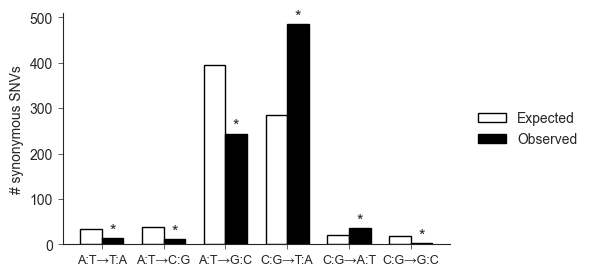

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(5 , 3))

df = sub_shift.set_index(["substitution type"]).loc[substitution_types]


expected = df["exp"].to_dict()
#expected = {st:row["exp"]/df["exp"].sum() for st, row in df.iterrows()}
observed = df["obs"].to_dict()
#observed = {st:row["obs"]/df["obs"].sum() for st, row in df.iterrows()}
siglabels = {st:"***" if row["p holm"]<0.001 else  "**" if row["p holm"]<0.01 else  "*"  if row["p holm"]<0.05 else "ns" for st,row in df.iterrows()}
siglabels = {st: "*"  if row["p holm"]<0.05 else "ns" for st,row in df.iterrows()}

x = np.arange(len(substitution_types))

width = 0.35

ax.bar(x - width / 2,[expected[s] for s in substitution_types], width, label="Expected", color="white", edgecolor="black")
bars = ax.bar(x + width / 2,[observed[s] for s in substitution_types], width, label="Observed", color="black", edgecolor="black")
for bar, sub_type in zip(bars, substitution_types):
    if siglabels[sub_type] != "ns":
        ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.025,
            siglabels[sub_type], ha="center", va="bottom", fontsize=12)
ax.spines[['top','right']].set_visible(False)
ax.set_ylabel("# synonymous SNVs", size=10)
ax.set_xticks(x)
ax.set_xticklabels(substitution_types, size=9)

leg = ax.legend(frameon=False, fontsize=10, loc='center left',
                        bbox_to_anchor=(1.04,0.5), ncols =1, handlelength=2, edgecolor=None, 
                        columnspacing=0.5)      


In [22]:
sub_shift.to_csv("../results/population_level_mutational_spectrum.csv", index=False)

In [23]:
substitution_change_results.to_csv("../results/mutation_bias_per_substitution_type_results.csv")

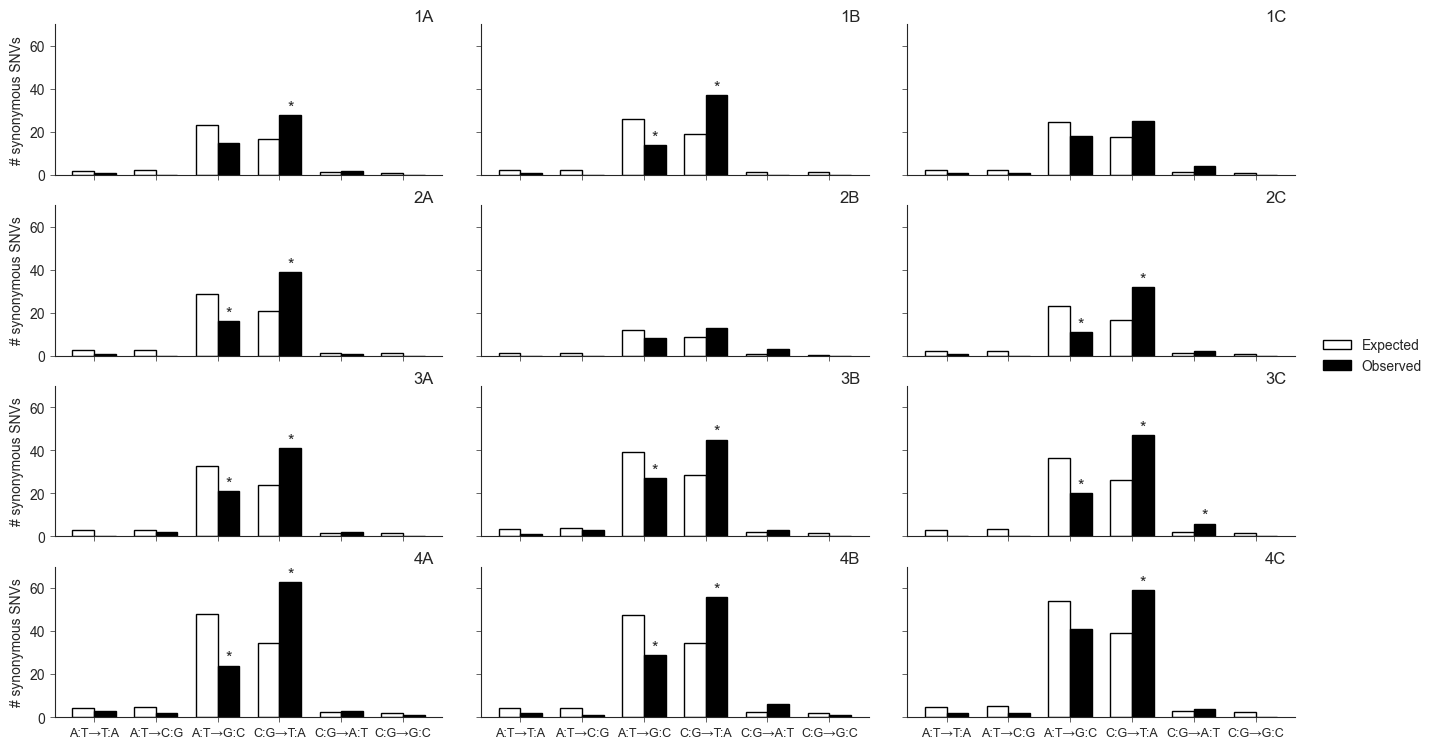

In [24]:
fig, axes = plt.subplots(len(donors), len(replicates), figsize=(4 * len(donors), 3 * len(replicates)), sharey=False)
fig.subplots_adjust(wspace=0.1)

for i, donor in enumerate(donors):
    for j, replicate in enumerate(replicates):
        ax = axes[i,j]
        population = f"{donor}{replicate}"
        
        df = substitution_change_results.loc[population].loc[substitution_types]
        expected = df["exp"].to_dict()
        #expected = {st:row["exp"]/df["exp"].sum() for st, row in df.iterrows()}
        observed = df["obs"].to_dict()
        #observed = {st:row["obs"]/df["obs"].sum() for st, row in df.iterrows()}
        siglabels = {st:"***" if row["p (two-sided holm-corrected)"]<0.001 else  "**" if row["p (two-sided holm-corrected)"]<0.01 else  "*"  if row["p (two-sided holm-corrected)"]<0.05 else "ns" for st,row in df.iterrows()}
        siglabels = {st: "*"  if row["p (two-sided holm-corrected)"]<0.05 else "ns" for st,row in df.iterrows()}
        
        x = np.arange(len(substitution_types))

        width = 0.35

        ax.bar(x - width / 2,[expected[s] for s in substitution_types], width, label="Expected", color="white", edgecolor="black")
        bars = ax.bar(x + width / 2,[observed[s] for s in substitution_types], width, label="Observed", color="black", edgecolor="black")
    
        for bar, sub_type in zip(bars, substitution_types):
            if siglabels[sub_type] != "ns":
                ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.025,
                    siglabels[sub_type], ha="center", va="bottom", fontsize=12)
        
        ax.set_ylim(0,70)
        ax.spines[['top','right']].set_visible(False)
        if j != 0:
            ax.set_yticklabels([])
        else:
            ax.set_ylabel("# synonymous SNVs", size=10)
        if i == 3:
            ax.set_xticks(x)
            ax.set_xticklabels(substitution_types, size=9)
        else:
            ax.set_xticklabels([])
       
        if i == 1 and j == 2:
                 
            leg = ax.legend(frameon=False, fontsize=10, loc='center left',
                        bbox_to_anchor=(1.04,0), ncols =1, handlelength=2, edgecolor=None, 
                        columnspacing=0.5)       
            
        ax.text(5.5, 70, population, ha="right", va="bottom")  
        
fig.savefig("../figures/figE4_mutational_spectrum_per_pop.svg", dpi=300,bbox_inches='tight')#
fig.savefig("../figures/figE4_mutational_spectrum_per_pop.png", dpi=300,bbox_inches='tight')   

**Extended Data Figure 4 Expected and observed mutational spectra for synonymous SNVs per population**. All synonymous SNVs in the non-overlapping ORFS of PB2, PB1, PA, HA, NP, and NA were included. Expected spectrum was calculated from the ancestral opportunity scaled by the total number of synonymous SNVs in the population, weighted according to the expected Ti/Tv ratio of 3. Asterisk indicates Holm-adjusted P<0.05(two-side binomial tests). Conclusions hold under the mean population-wide estimated Ti/Tv ratio of 11.75

#### 1.3.2. Overlapping ORFS

In [25]:
#determine opportunity based on stock   
TnTv = 3
weight_Tn = 3 * TnTv / (1 + TnTv)
weight_Tv = (3 - weight_Tn) / 2

target_genes = ["PB2", "PB1", "PA", "NP", "HA", "NP","NA", "M1", "M2", "NS1", "NEP"]            
opportunity_overall = defaultdict(float)
for segment, sdict in coding_json.items():
    for gene, gdict in sdict.items():
        if gene not in target_genes:
            continue

        gene_seq = Seq("".join([b for i, b in enumerate(segment_nuc_cds[segment])if i + 1 in gdict['nuc_cds_pos']]))
        gene_codons = [str(gene_seq[i:i + 3]) for i in range(0, len(gene_seq), 3)]

        for codon in gene_codons:
            if len(codon) != 3 or any(b not in "ACGT" for b in codon):
                continue
            for sub_type, w in get_synonymous_weights_by_subtype(codon).items():
                
                opportunity_overall[sub_type] += w

total_opportunity_overall = sum(opportunity.values())


In [26]:
#per population
df = snv_summary[(snv_summary["non_synonymous"] == False) &(snv_summary["protein"].isin(target_genes))].copy()

df["anc_base"] = df["nuc_change"].str[0]
df["sub_type"] = df.apply(lambda r: canonical_sub(r["anc_base"], r["read_base"]), axis=1)


substitution_change_results_overall = []
for population in populations:
    sdf = df.loc[population]
    n_muts = len(sdf)

    obs_counts = sdf["sub_type"].value_counts().to_dict()
    observed = {s: obs_counts.get(s, 0) for s in substitution_types}

    # print(f"\n=== {population} (n={n_muts}) ===")
    # print(f"{'Substitution':<20} {'Obs':>6} {'Exp':>8} {'p (two-sided)':>15} {'p (greater)':>12} {'p (less)':>12}")
    # print("-" * 77)

    obs_list, exp_list = [], []
    res = []
    for sub_type in substitution_types: 
        obs = observed[sub_type]
        p_exp = opportunity[sub_type] / total_opportunity_overall
        exp = p_exp * n_muts
        result_two = binomtest(k=obs, n=n_muts, p=p_exp, alternative="two-sided")
        result_gt  = binomtest(k=obs, n=n_muts, p=p_exp, alternative="greater")
        result_ls  = binomtest(k=obs, n=n_muts, p=p_exp, alternative="less")
        
        sig_two = "*" if result_two.pvalue < 0.05 else ""
        sig_gt  = "*" if result_gt.pvalue  < 0.05 else ""
        sig_ls  = "*" if result_ls.pvalue  < 0.05 else ""
        
        # print(f"{sub_type:<20} {obs:>6} {exp:>8.2f} {result_two.pvalue:>14.4f}{sig_two:1} {result_gt.pvalue:>11.4f}{sig_gt:1} {result_ls.pvalue:>11.4f}{sig_ls:1}")
        
        #substitution_change_results.append([population, sub_type, obs, exp, result_two.pvalue, result_gt.pvalue, result_ls.pvalue])
        res.append([population, sub_type, obs, exp, result_two.pvalue, result_gt.pvalue, result_ls.pvalue])
        
        obs_list.append(obs)
        exp_list.append(exp)
    res = pd.DataFrame.from_records(res, columns=["population", "substitution type", "obs", "exp", "p (two-sided)", "p (greater)", "p (less)"])#.set_index(["population", "substitution type"]).sort_index()
    res["p (two-sided holm-corrected)"] = multipletests(res["p (two-sided)"], method="holm")[1]
    
    try:
        substitution_change_results_overall = pd.concat([substitution_change_results_overall, res], ignore_index=True)
    except TypeError:
        substitution_change_results_overall = res
        
    chi2, p = chisquare(f_obs=obs_list, f_exp=exp_list)
    p_result = f"{p:.2e}" if p < 0.01 else f"{p:.4f}"
    print(f"{population}, chi2: {chi2:.2f},  p-value: {p_result}")

#substitution_change_results = pd.DataFrame.from_records(substitution_change_results, columns=["population", "substitution type", "obs", "exp", "p (two-sided)", "p (greater)", "p (less)"]).set_index(["population", "substitution type"]).sort_index()
substitution_change_results_overall = substitution_change_results_overall.set_index(["population", "substitution type"]).sort_index()
substitution_change_results_overall["sig"] = [True if p< 0.05 else False for p in substitution_change_results_overall["p (two-sided holm-corrected)"]]


1A, chi2: 18.18,  p-value: 2.72e-03
1B, chi2: 18.85,  p-value: 2.05e-03
1C, chi2: 15.36,  p-value: 8.94e-03
2A, chi2: 36.84,  p-value: 6.45e-07
2B, chi2: 22.93,  p-value: 3.49e-04
2C, chi2: 30.08,  p-value: 1.43e-05
3A, chi2: 21.50,  p-value: 6.51e-04
3B, chi2: 24.60,  p-value: 1.67e-04
3C, chi2: 48.58,  p-value: 2.71e-09
4A, chi2: 36.00,  p-value: 9.51e-07
4B, chi2: 30.32,  p-value: 1.28e-05
4C, chi2: 30.01,  p-value: 1.47e-05


In [27]:
n_subs = substitution_change_results_overall.reset_index().pivot(index="population", columns="substitution type", values="obs")

n_subs.to_csv("../results/snvs_per_subtype_per_pop_matrix_overall.csv")

In [28]:
pooled_sub_counts_overall = substitution_change_results_overall.groupby("substitution type")[["obs"]].sum()

sub_shift_overall = []
n_total = pooled_sub_counts_overall["obs"].sum()

for sub_type, row in pooled_sub_counts_overall.iterrows():
    p_exp = opportunity[sub_type] / total_opportunity_overall
    exp = p_exp * n_total

    
    result_two = binomtest(k=int(row["obs"]), n=n_total, p=p_exp, alternative="two-sided")
    ci = result_two.proportion_ci(0.95, method="exact")
    sub_shift_overall.append([sub_type,row["obs"], exp, result_two.pvalue, int(row["obs"])/exp, ci[0]/p_exp, ci[1]/p_exp ])

sub_shift_overall = pd.DataFrame.from_records(sub_shift_overall , columns=["substitution type", "obs", "exp", "p",  "obs/exp", "lower 95%-CI", "upper 95% CI"])  
sub_shift_overall["p holm"] = multipletests(sub_shift["p"], method="holm")[1]

# # # chi square
# chi2, p= chisquare(f_obs=sub_shift["obs"], f_exp=sub_shift["exp"])
# p_result = f"{p:.2e}" if p < 0.01 else f"{p:.4f}"
# print(f"chi2: {chi2:.2f},  p-value: {p_result}")

sub_shift_overall["sig"] = [True if p <0.05 else False for p in sub_shift["p holm"]]
sub_shift_overall["p holm manu"] = [f"{p:.2e}" if p < 0.001 else f"{p:.4f}"for p in sub_shift["p holm"]]
sub_shift_overall

,substitution type,obs,exp,p,obs/exp,lower 95%-CI,upper 95% CI,p holm,sig,p holm manu
0,A:T→C:G,13,44.095268,4.557657e-08,0.294816,0.157409,0.501638,1.594029e-06,True,1.59e-06
1,A:T→G:C,287,463.709182,8.715823e-32,0.618922,0.559624,0.680655,7.760937e-27,True,7.76e-27
2,A:T→T:A,16,40.169226,1.675586e-05,0.398315,0.228394,0.643358,9.928979e-05,True,9.93e-05
3,C:G→A:T,45,24.210592,1.136117e-04,1.858691,1.364045,2.466559,1.611651e-03,True,0.0016
4,C:G→G:C,2,20.357255,4.837117e-07,0.098245,0.011903,0.353897,2.460369e-05,True,2.46e-05
5,C:G→T:A,565,335.458477,1.169360e-52,1.684262,1.595069,1.771538,9.033797e-46,True,9.03e-46


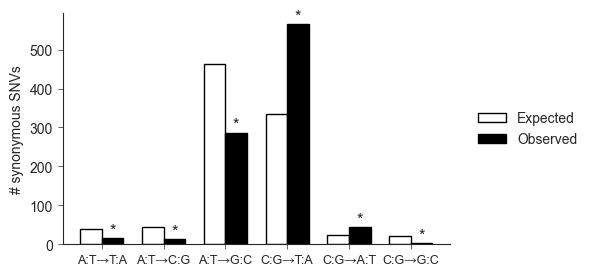

In [29]:
fig, ax = plt.subplots(1, 1, figsize=(5 , 3))

df = sub_shift_overall.set_index(["substitution type"]).loc[substitution_types]


expected = df["exp"].to_dict()
#expected = {st:row["exp"]/df["exp"].sum() for st, row in df.iterrows()}
observed = df["obs"].to_dict()
#observed = {st:row["obs"]/df["obs"].sum() for st, row in df.iterrows()}
siglabels = {st:"***" if row["p holm"]<0.001 else  "**" if row["p holm"]<0.01 else  "*"  if row["p holm"]<0.05 else "ns" for st,row in df.iterrows()}
siglabels = {st: "*"  if row["p holm"]<0.05 else "ns" for st,row in df.iterrows()}

x = np.arange(len(substitution_types))

width = 0.35

ax.bar(x - width / 2,[expected[s] for s in substitution_types], width, label="Expected", color="white", edgecolor="black")
bars = ax.bar(x + width / 2,[observed[s] for s in substitution_types], width, label="Observed", color="black", edgecolor="black")
for bar, sub_type in zip(bars, substitution_types):
    if siglabels[sub_type] != "ns":
        ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.025,
            siglabels[sub_type], ha="center", va="bottom", fontsize=12)
ax.spines[['top','right']].set_visible(False)
ax.set_ylabel("# synonymous SNVs", size=10)
ax.set_xticks(x)
ax.set_xticklabels(substitution_types, size=9)

leg = ax.legend(frameon=False, fontsize=10, loc='center left',
                        bbox_to_anchor=(1.04,0.5), ncols =1, handlelength=2, edgecolor=None, 
                        columnspacing=0.5)      


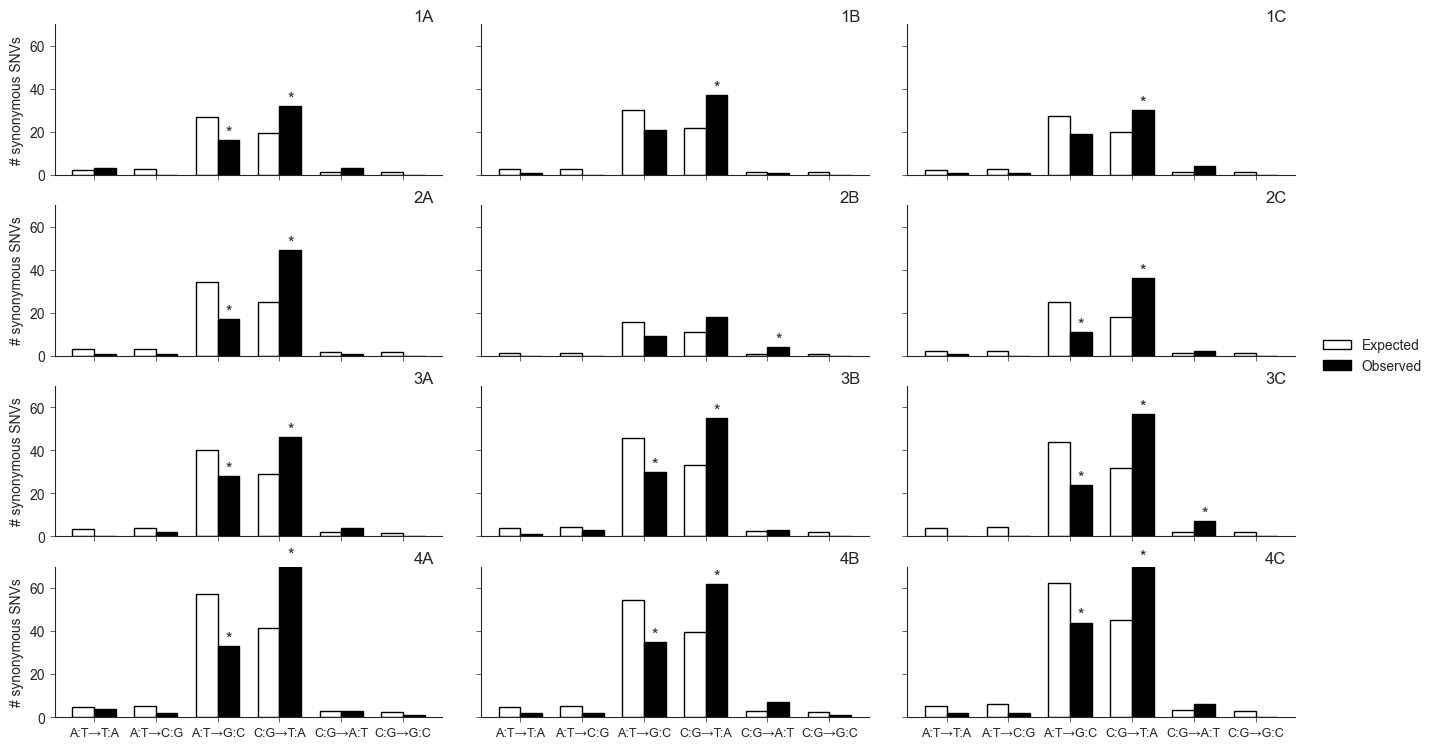

In [30]:
fig, axes = plt.subplots(len(donors), len(replicates), figsize=(4 * len(donors), 3 * len(replicates)), sharey=False)
fig.subplots_adjust(wspace=0.1)

for i, donor in enumerate(donors):
    for j, replicate in enumerate(replicates):
        ax = axes[i,j]
        population = f"{donor}{replicate}"
        
        df = substitution_change_results_overall.loc[population].loc[substitution_types]
        expected = df["exp"].to_dict()
        #expected = {st:row["exp"]/df["exp"].sum() for st, row in df.iterrows()}
        observed = df["obs"].to_dict()
        #observed = {st:row["obs"]/df["obs"].sum() for st, row in df.iterrows()}
        siglabels = {st:"***" if row["p (two-sided holm-corrected)"]<0.001 else  "**" if row["p (two-sided holm-corrected)"]<0.01 else  "*"  if row["p (two-sided holm-corrected)"]<0.05 else "ns" for st,row in df.iterrows()}
        siglabels = {st: "*"  if row["p (two-sided holm-corrected)"]<0.05 else "ns" for st,row in df.iterrows()}
        
        x = np.arange(len(substitution_types))

        width = 0.35

        ax.bar(x - width / 2,[expected[s] for s in substitution_types], width, label="Expected", color="white", edgecolor="black")
        bars = ax.bar(x + width / 2,[observed[s] for s in substitution_types], width, label="Observed", color="black", edgecolor="black")
    
        for bar, sub_type in zip(bars, substitution_types):
            if siglabels[sub_type] != "ns":
                ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() + 0.025,
                    siglabels[sub_type], ha="center", va="bottom", fontsize=12)
        
        ax.set_ylim(0,70)
        ax.spines[['top','right']].set_visible(False)
        if j != 0:
            ax.set_yticklabels([])
        else:
            ax.set_ylabel("# synonymous SNVs", size=10)
        if i == 3:
            ax.set_xticks(x)
            ax.set_xticklabels(substitution_types, size=9)
        else:
            ax.set_xticklabels([])
       
        if i == 1 and j == 2:
                 
            leg = ax.legend(frameon=False, fontsize=10, loc='center left',
                        bbox_to_anchor=(1.04,0), ncols =1, handlelength=2, edgecolor=None, 
                        columnspacing=0.5)       
            
        ax.text(5.5, 70, population, ha="right", va="bottom")  
        
        

In [31]:
df =substitution_change_results_overall.copy()[["obs", "exp", "p (two-sided holm-corrected)"]].rename(columns={"p (two-sided holm-corrected)":"p"})
df.reset_index().pivot(index=["population"], columns=["substitution type"], values=["obs", "exp", "p"]).swaplevel(axis=1).sort_index(axis=1)

substitution type   A:T→C:G                   A:T→G:C                  \
                        exp  obs         p        exp   obs         p   
population                                                              
1A                 2.565888  0.0  0.666830  26.983077  16.0  0.019193   
1B                 2.850987  0.0  0.475105  29.981197  21.0  0.136710   
1C                 2.613405  1.0  1.000000  27.482764  19.0  0.150154   
2A                 3.278635  1.0  1.000000  34.478377  17.0  0.000147   
2B                 1.473010  0.0  1.000000  15.490285   9.0  0.117801   
2C                 2.375823  0.0  0.702446  24.984331  11.0  0.000451   
3A                 3.801316  2.0  0.852354  39.974929  28.0  0.048420   
3B                 4.371514  3.0  1.000000  45.971169  30.0  0.005556   
3C                 4.181448  0.0  0.068301  43.972422  24.0  0.000119   
4A                 5.464392  2.0  0.731353  57.463961  33.0  0.000028   
4B                 5.179293  2.0  0.756993  54.465841  35.0  0.001188   
4C                 5.939557  2.0  0.482357  62.460827  44.0  0.005964   

substitution type   A:T→T:A                  C:G→A:T                  C:G→G:C  \
                        exp  obs         p       exp  obs         p       exp   
population                                                                      
1A                 2.337433  3.0  1.000000  1.408806  3.0  0.666830  1.184582   
1B                 2.597148  1.0  1.000000  1.565340  1.0  1.000000  1.316202   
1C                 2.380719  1.0  1.000000  1.434895  4.0  0.221219  1.206518   
2A                 2.986720  1.0  1.000000  1.800141  1.0  1.000000  1.513632   
2B                 1.341860  0.0  1.000000  0.808759  4.0  0.049829  0.680038   
2C                 2.164290  1.0  1.000000  1.304450  2.0  1.000000  1.096835   
3A                 3.462864  0.0  0.206011  2.087120  4.0  0.469904  1.754936   
3B                 3.982294  1.0  0.769055  2.400188  3.0  1.000000  2.018176   
3C                 3.809151  0.0  0.068767  2.295832  7.0  0.033201  1.930429   
4A                 4.977867  4.0  1.000000  3.000235  3.0  1.000000  2.522720   
4B                 4.718153  2.0  0.756993  2.843701  7.0  0.097883  2.391100   
4C                 5.410725  2.0  0.482357  3.261125  6.0  0.482357  2.742087   

substitution type                   C:G→T:A                      
                   obs         p        exp   obs             p  
population                                                       
1A                 0.0  1.000000  19.520213  32.0  3.538570e-03  
1B                 0.0  1.000000  21.689126  37.0  4.224101e-04  
1C                 0.0  1.000000  19.881699  30.0  4.225770e-02  
2A                 0.0  1.000000  24.942495  49.0  4.656131e-08  
2B                 0.0  1.000000  11.206048  18.0  7.199799e-02  
2C                 0.0  1.000000  18.074271  36.0  2.102623e-06  
3A                 0.0  0.852354  28.918834  46.0  6.337929e-04  
3B                 0.0  0.822346  33.256659  55.0  3.416173e-05  
3C                 0.0  0.270466  31.810718  57.0  4.623097e-07  
4A                 1.0  1.000000  41.570824  72.0  8.325425e-08  
4B                 1.0  0.756993  39.401912  62.0  8.156393e-05  
4C                 0.0  0.482357  45.185678  71.0  2.187437e-05

## 2. Codon usage bias

### 2.1. Estimate codon usage bias in starting virus 
I have also explored codon usage in global data (all, pre-2008, and post-2008) but found no difference, so using starting virus for simplicity

In [32]:
aa_codons = {aa:[codon for codon, a in codon_table.items() if a == aa] for aa in set(codon_table.values())}

codon_usage = {protein:{codon:0 for codon in codon_table.keys()} for protein in proteins+ ["genome"]}
for segment, pposdict in aapos2codon.items():
    seq = segment_nuc_cds[segment]
    for protein, posdict in pposdict.items():
        for aapos, codon_positions in posdict.items():
            codon = "".join([seq[p-1] for p in codon_positions])
            codon_usage[protein][codon] += 1
            codon_usage["genome"][codon] += 1
            
starting_codon_usage = []
for protein, codon_dict in codon_usage.items():
    codon_count = sum(codon_dict.values())  
    for codon, c in codon_dict.items():
        starting_codon_usage.append([protein, codon, c, c/codon_count])

starting_codon_usage = pd.DataFrame.from_records(starting_codon_usage, columns=["protein", "codon", "count", "proportion"])
#starting_codon_usage.pivot(index="protein", columns="codon", values="proportion")       
        


In [33]:
snv_summary[snv_summary['non_synonymous']==False]["protein"].unique()

array(['PB2', 'PB1', 'PB1-F2', 'PA', 'PA-X', 'HA', 'NP', 'NA', 'M1', 'M2',
       'NS1', 'NEP'], dtype=object)

In [34]:
starting_codon_usage_df = starting_codon_usage.pivot(index="protein", columns="codon", values="proportion")

synonymous_snvs_overview =  snv_summary[snv_summary['non_synonymous']==False].reset_index()

for i, row in synonymous_snvs_overview.iterrows():
    possible_codons=  codons_per_aa[row["aa_mut"][-1]]
    codon = row["original_codon"]
    
    #segment > well protein preferred
    protein_usage = starting_codon_usage_df.loc[row["protein"], possible_codons].to_dict()
    protein_preferred = [k for k, v in protein_usage.items() if v == max(protein_usage.values())][0]
    #get preferrence
    pref = "toward preferred" if row["read_codon"] == protein_preferred else "from preferred" if codon==protein_preferred else "neutral"
    synonymous_snvs_overview.loc[i, "codon change protein"] = pref
    
    #genome wide preference
    genome_usage = starting_codon_usage_df.loc["genome", possible_codons].to_dict()
    genome_preferred = [k for k, v in genome_usage.items() if v == max(genome_usage.values())][0]
    #get preferrence
    pref = "toward preferred" if row["read_codon"] == genome_preferred else "from preferred" if codon==genome_preferred else "neutral"
    synonymous_snvs_overview.loc[i, "codon change genome"] = pref
        

In [35]:
#get proportions
codon_change_columns = ['codon change genome', ]
new_labels = ["starting virus"]
codon_change_cats = synonymous_snvs_overview["codon change genome"].unique().tolist()

codon_change_proportions = []
df = synonymous_snvs_overview.groupby(["population",'codon change genome'])[["snv"]].count()
for population in populations:
    tot = df.loc[population]["snv"].sum()
    for change in codon_change_cats:
        prop = df.loc[(population, change), "snv"] / tot
        codon_change_proportions.append([population, "stock", change, prop, "all"])


for status in ["drift", "transient", "fixed"]:
    df = synonymous_snvs_overview[synonymous_snvs_overview["status"]==status].groupby(["population",'codon change genome'])[["snv"]].count()
    for population in populations:
        tot = df.loc[population]["snv"].sum()
        for change in codon_change_cats:
            try:
                prop = df.loc[(population, change), "snv"] / tot
            except:
                prop = 0
            codon_change_proportions.append([population, "stock", change, prop, status])   
                
codon_change_proportions = pd.DataFrame(codon_change_proportions, columns=["population", "reference", "change", "proportion", "status"])
codon_change_proportions = codon_change_proportions.pivot(index=["reference", "population", "change"], columns=["status"], values="proportion")


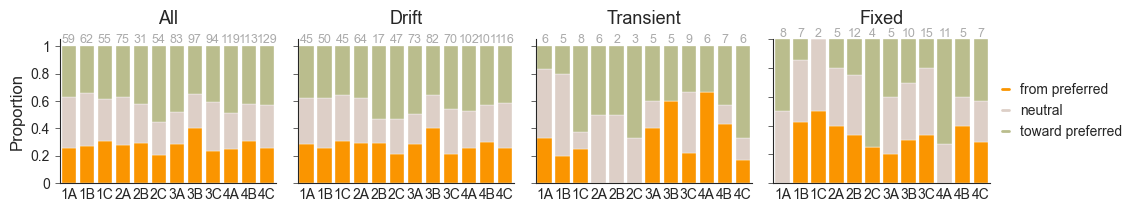

In [36]:
fig = plt.figure(figsize=(12, 7))
gs = gridspec.GridSpec(2,1, wspace=0.45, hspace=0.5 ,height_ratios=[1,2])
possible_preferences = ["from preferred", "neutral", "toward preferred"]
cpal = ["#babd8d","#ddcfc7","#fa9500"][::-1]

label_counts = True

axes = []
ref= "stock"
gsi = gridspec.GridSpecFromSubplotSpec(1,4, wspace=0.1, hspace=0.13, subplot_spec=gs[0])
for i, status in enumerate(["all", "drift", "transient", "fixed"]):
    ax = fig.add_subplot(gsi[i])
    for pi, population in enumerate(populations):
        df = codon_change_proportions.loc[(ref, population)]
        bottom = 0
        for pj,  mt in enumerate(possible_preferences):
            try:
                c = df.loc[mt, status]
            except:
                c = 0

            p = ax.bar(pi+0.5, c, bottom=bottom, color=cpal[pj], edgecolor=None, lw=0.25)
            bottom += c
        if label_counts:
            cdf = synonymous_snvs_overview[synonymous_snvs_overview["population"]==population]
            if status != "all":
                cdf = cdf[cdf["status"]==status]
            ax.text(pi+0.5, 1, len(cdf) , va="bottom", ha="center",  size=9, color="#ABABAB")
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1]) 
    if i ==0:
        ax.set_yticklabels([0, 0.2, 0.4, 0.6, 0.8, 1], size=10) 
        ax.set_ylabel("Proportion", size=12)
    else:
        ax.set_yticklabels([])
            
    axes.append(ax)
    ax.set_title(status.capitalize(),  y=1.05, size=13)
    

for i, ax in enumerate(axes):
    

    ax.set_xlim(0,len(populations))
    ax.set_xticks([i+0.5 for i in range(len(populations))])
    ax.tick_params(axis='x', which='both', length=0)
    if i in [0,1,2,3,6,9,12,15]:
        ax.set_xticklabels(populations, size=10)
    else:
        ax.set_xticklabels([])
    ax.spines[['top','right']].set_visible(False)  

legend_elements = []
for (mt, color) in zip(possible_preferences, cpal):
    legend_elements.append(Line2D([0], [0], color=color, label=mt, linewidth=2,  ))
leg = axes[3].legend(handles=legend_elements, loc='center left',
                        bbox_to_anchor=(1,0.5), ncols =1, fontsize=10, handlelength=0.5, edgecolor=None, frameon=False, 
                        columnspacing=0.5)         

        
fig.savefig("../figures/figE6_direction_of_codon_change.svg", dpi=300,bbox_inches='tight')#
fig.savefig("../figures/figE6_direction_of_codon_change.png", dpi=300,bbox_inches='tight') 

**Extended Data Figure 6 Direction of codon change and associated nucleotide change for synonymous SNVs.** Direction of codon change relative to the preferred codon in the starting virus sequence for all and drift, non-drift, and fixed synonymous SNV per population.

## 3. Annotate summary

In [37]:
for (population, refname, nucpos, snv) in snv_summary.index:
    if snv[0] == "G" and snv[-1] == "A": 
        snv_summary.loc[(population, refname, nucpos, snv), "mutation bias"] = "G>A"
    if snv[0] == "C" and snv[-1] == "T": 
        snv_summary.loc[(population, refname, nucpos, snv), "mutation bias"] = "C>T"

In [38]:
snv_summary.to_csv("../results/snv_summary_annotated_linkage_bias.csv")

### 3.1. numbers 

In [39]:
df = snv_summary[(snv_summary["status"]!="drift")&(~snv_summary["mutation bias"].isna())]
df = df.drop(columns=["protein", "aapos", "aa_mut", "non_synonymous", "original_codon",	'read_codon',	"position_in_codon" ]).reset_index().drop_duplicates()
df.reset_index().groupby(["population"])["snv"].count()

population
1A    12
1B    13
1C    14
2A    11
2B     9
2C    14
3A     9
3B    13
3C    19
4A    17
4B     9
4C    12
Name: snv, dtype: int64

In [40]:
#percentage
tdf = snv_summary[snv_summary["status"]!="drift"].drop(columns=["protein", "aapos", "aa_mut", "non_synonymous", "original_codon",	'read_codon',	"position_in_codon" ]).reset_index().drop_duplicates()
((df.reset_index().groupby(["population"])["snv"].count() / tdf.reset_index().groupby(["population"])["snv"].count()) *100)

population
1A    57.142857
1B    56.521739
1C    66.666667
2A    64.705882
2B    47.368421
2C    87.500000
3A    60.000000
3B    54.166667
3C    57.575758
4A    65.384615
4B    50.000000
4C    54.545455
Name: snv, dtype: float64

In [41]:
#see which also are labelled as hitchhikers
df = snv_summary[~snv_summary.index.isin(snv_summary[(snv_summary["hitchhiker"].isna())&(snv_summary["cooccurence"].isna())].index.tolist())]
df = df[(df["status"]!="drift")&(~df["mutation bias"].isna())].drop(columns=["protein", "aapos", "aa_mut", "non_synonymous", "original_codon",	'read_codon',	"position_in_codon" ]).reset_index().drop_duplicates()
df.reset_index().groupby(["population"])["snv"].count() 

population
1A    2
1B    1
1C    1
2A    5
2B    2
2C    5
3A    3
3B    4
3C    8
4A    6
4B    1
4C    3
Name: snv, dtype: int64